# **HUMAN SCREAM DETECTION**

In [ ]:
# Installing  libraries 
!pip install librosa pandas scikit-learn tensorflow matplotlib resampy



import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 53.5 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 54.1 MB/s eta 0:00:00
  Attempting uninstall: keras
    Found existing installation: keras 3.4.1
    Uninstalling keras-3.4.1:
      Successfully uninstalled keras-3.4.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow-decision-forests 1.8.1 requires wurlitzer, which is not installed.
/kaggle/input/prediction/-ECK_BisOLM_out.wav
/kaggle/input/prediction/-Wu-WkTumEM_out.wav
/kaggle/input/prediction/-Dj2PfPmynQ_out.wav
/kaggle/input/prediction/-HN5kqCKpEA_out.wav
/kaggle/input/prediction/-5Jlimvsuwo_out.wav
/kaggle/input/prediction/-KiAK66YwW8_out.wav
/kaggle/input/prediction/-CgdUiJaNdU_out.wav
/kaggle/input/audio-dataset-of-scream-and-non-scream/Converted_Separately/scream/611.wav
/kaggle/input/audio-dataset-of-screa

In [2]:
import librosa
import numpy as np
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
import time
import os
import numpy as np
import joblib
#import sounddevice as sd
#from joblib import Parallel, delayed
#import gc  # For garbage collection to free memory

In [3]:
import torch
print(torch.cuda.is_available())

False


**Directories for Screaming and Not Screaming datasets**

In [4]:

scream_dir = "/kaggle/input/audio-dataset-of-scream-and-non-scream/Converted_Separately/scream"
non_scream_dir = "/kaggle/input/audio-dataset-of-scream-and-non-scream/Converted_Separately/non_scream"
screaming_dir = "/kaggle/input/human-screaming-detection-dataset/Screaming"
not_screaming_dir = "/kaggle/input/human-screaming-detection-dataset/NotScreaming"

RATE = 44100  # Sample rate

**Extracting the Features from the DataSets**

This function extracts various audio features from an input audio signal, including MFCCs, spectral contrast, chroma, and others.

In [5]:
def extract_single_audio_features(y):
    """Extracts various audio features including MFCCs, spectral contrast, chroma features, and more."""
    
    # Extract MFCCs (Mel-frequency cepstral coefficients)
    mfccs = librosa.feature.mfcc(y=y, sr=RATE, n_mfcc=13)
    
    # Extract Spectral Contrast
    spectral_contrast = librosa.feature.spectral_contrast(y=y, sr=RATE)
    
    # Extract Chroma Features
    chroma = librosa.feature.chroma_stft(y=y, sr=RATE)
    
    # Extract Zero Crossing Rate
    zero_crossing_rate = librosa.feature.zero_crossing_rate(y)
    
    # Extract Spectral Centroid
    spectral_centroid = librosa.feature.spectral_centroid(y=y, sr=RATE)
    
    # Extract Spectral Bandwidth
    spectral_bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=RATE)
    
    # Extract Root Mean Square Energy (RMSE)
    rmse = librosa.feature.rms(y=y)
    
    # Extract Spectral Roll-off
    spectral_rolloff = librosa.feature.spectral_rolloff(y=y, sr=RATE)
    
    # Extract Tempo (Beats Per Minute)
    onset_env = librosa.onset.onset_strength(y=y, sr=RATE)
    tempo = librosa.beat.tempo(onset_envelope=onset_env, sr=RATE)
    
    # Concatenate all the features into a single feature vector
    feature_vector = np.hstack([
        np.mean(mfccs, axis=1),             # MFCCs
        np.mean(spectral_contrast, axis=1), # Spectral Contrast
        np.mean(chroma, axis=1),            # Chroma
        np.mean(zero_crossing_rate),        # Zero Crossing Rate
        np.mean(spectral_centroid),         # Spectral Centroid
        np.mean(spectral_bandwidth),        # Spectral Bandwidth
        np.mean(rmse),                      # RMSE
        np.mean(spectral_rolloff),          # Spectral Roll-off
        tempo                               # Tempo (BPM)
    ])
    
    return feature_vector

In [6]:
import numpy as np
import librosa
import os
import glob

# Constants
SAMPLE_RATE = 44100  # Sample rate for audio files
TARGET_LENGTH = 2048  # Desired length for padding/truncating

# Function to load and process audio files
def load_and_process_audio_files(directory):
    audio_files = glob.glob(os.path.join(directory, '*.wav'))  # Adjust the extension as needed
    features = []

    for file in audio_files:
        signal, sr = librosa.load(file, sr=SAMPLE_RATE)
        # Example feature extraction: use MFCCs, or modify as per your needs
        mfccs = librosa.feature.mfcc(y=signal, sr=sr, n_mfcc=13)
        features.append(mfccs)

    return np.array(features)

# Function to augment audio signals
def augment_sound(signal):
    # Simple augmentation techniques, e.g., pitch shifting, time stretching, etc.
    augmented = []
    augmented.append(librosa.effects.pitch_shift(signal, n_steps=4, sr=SAMPLE_RATE))  # Pitch shift
    augmented.append(librosa.effects.time_stretch(signal, rate=1.5))  # Time stretch
    return augmented

# Function to pad or truncate signals to a fixed length
def pad_or_truncate(signal, target_length):
    if len(signal) < target_length:
        # Pad with zeros if signal is shorter
        return np.pad(signal, (0, target_length - len(signal)), mode='constant')
    else:
        # Truncate if signal is longer
        return signal[:target_length]

# Step 1: Load and process scream audio files
print("Loading and processing scream audio files...")
X_screams_1 = load_and_process_audio_files('path_to_screaming_dir_1')
print("1/2")
X_screams_2 = load_and_process_audio_files('path_to_screaming_dir_2')
print("2/2")

# Combine scream datasets from both directories
X_screams = np.vstack([X_screams_1, X_screams_2])
print("Scream audio files processed and features extracted.")

# Augment scream data
augmented_screams = []
for sound in X_screams:
    # Assuming sound is in the correct format (1D array for each audio file)
    augmented_sounds = augment_sound(sound)
    for aug_sound in augmented_sounds:
        padded_augmented_sound = pad_or_truncate(aug_sound, TARGET_LENGTH)
        augmented_screams.append(padded_augmented_sound)

# Convert augmented sounds to numpy array
X_augmented_screams = np.array(augmented_screams)

# Step 2: Load and process non-scream audio files
print("Loading and processing non-scream audio files...")
X_non_screams_1 = load_and_process_audio_files('path_to_not_screaming_dir_1')
print("1/2")
X_non_screams_2 = load_and_process_audio_files('path_to_non_scream_dir_2')
print("2/2")

# Combine non-scream datasets from both directories
X_non_screams = np.vstack([X_non_screams_1, X_non_screams_2])
print("Non-scream audio files processed and features extracted.")

# Augment non-scream data
augmented_non_screams = []
for sound in X_non_screams:
    augmented_sounds = augment_sound(sound)
    for aug_sound in augmented_sounds:
        padded_augmented_sound = pad_or_truncate(aug_sound, TARGET_LENGTH)
        augmented_non_screams.append(padded_augmented_sound)

# Convert augmented non-scream sounds to numpy array
X_augmented_non_screams = np.array(augmented_non_screams)

# Combine augmented datasets
X_combined = np.vstack([X_augmented_screams, X_augmented_non_screams])
print("Combined features shape after augmentation:")
print(f"Scream features shape: {X_augmented_screams.shape}")
print(f"Non-scream features shape: {X_augmented_non_screams.shape}")
print(f"Combined features shape: {X_combined.shape}")

# Continue with your model training or further processing...


Loading and processing scream audio files...
1/2
2/2
Scream audio files processed and features extracted.


/opt/conda/lib/python3.10/site-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=0
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=0
  warnings.warn(


Loading and processing non-scream audio files...
1/2
2/2
Non-scream audio files processed and features extracted.
Combined features shape after augmentation:
Scream features shape: (4, 2048)
Non-scream features shape: (4, 2048)
Combined features shape: (8, 2048)


/opt/conda/lib/python3.10/site-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=0
  warnings.warn(


In [7]:
import numpy as np
import librosa
import os

# Constants for audio processing
SAMPLE_RATE = 22050  # Sample rate of audio files
TARGET_LENGTH = 100  # Length to pad/truncate MFCCs (adjust based on your needs)

def load_and_process_audio_files(directory):
    features = []
    for filename in os.listdir(directory):
        if filename.endswith('.wav'):  # Change based on your audio file format
            file_path = os.path.join(directory, filename)
            # Load audio file
            signal, sr = librosa.load(file_path, sr=SAMPLE_RATE)
            # Perform feature extraction (e.g., MFCCs)
            mfccs = librosa.feature.mfcc(y=signal, sr=sr, n_mfcc=13)
            
            # Pad or truncate MFCCs to ensure consistent shape
            if mfccs.shape[1] < TARGET_LENGTH:
                padded_mfccs = np.pad(mfccs, ((0, 0), (0, TARGET_LENGTH - mfccs.shape[1])), mode='constant')
            else:
                padded_mfccs = mfccs[:, :TARGET_LENGTH]  # Truncate if too long
            
            features.append(padded_mfccs)
    
    return np.array(features)

# Step 1: Load and process scream audio files
print("Loading and processing scream audio files...")
X_screams_1 = load_and_process_audio_files(screaming_dir)
print("1/2")
X_screams_2 = load_and_process_audio_files(scream_dir)
print("2/2")
    
# Combine scream datasets from both directories
X_screams = np.vstack([X_screams_1, X_screams_2])
print("Scream audio files processed and features extracted.")
    
# Step 2: Load and process non-scream audio files
print("Loading and processing non-scream audio files...")
X_non_screams_1 = load_and_process_audio_files(not_screaming_dir)
print("1/2")
X_non_screams_2 = load_and_process_audio_files(non_scream_dir)
print("2/2")
    
# Combine non-scream datasets from both directories
X_non_screams = np.vstack([X_non_screams_1, X_non_screams_2])
print("Non-scream audio files processed and features extracted.")
    
# Now you can proceed with model training using X_screams and X_non_screams
print(f"Scream features shape: {X_screams.shape}")
print(f"Non-scream features shape: {X_non_screams.shape}")


Loading and processing scream audio files...
1/2
2/2
Scream audio files processed and features extracted.
Loading and processing non-scream audio files...
1/2
2/2
Non-scream audio files processed and features extracted.
Scream features shape: (2445, 13, 100)
Non-scream features shape: (4176, 13, 100)


In [8]:
print(f"Scream features shape: {X_screams.shape}")

Scream features shape: (2445, 13, 100)


This combines all the processed audio features and labels into single arrays.

In [9]:
print("Number of features in X_screams:", X_screams.shape[1])
print("Number of features in X_non_screams:", X_non_screams.shape[1])


Number of features in X_screams: 13
Number of features in X_non_screams: 13


**MFCC Coefficients:**

**MFCC1: Represents the overall energy or loudness of the signal.
MFCC2-13 (or more): Represent the spectral envelope of the signal, capturing information about the shape and distribution of the frequency components.**

Shape of X_screams: (2445, 13, 100)
Shape of X_non_screams: (4176, 13, 100)


/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

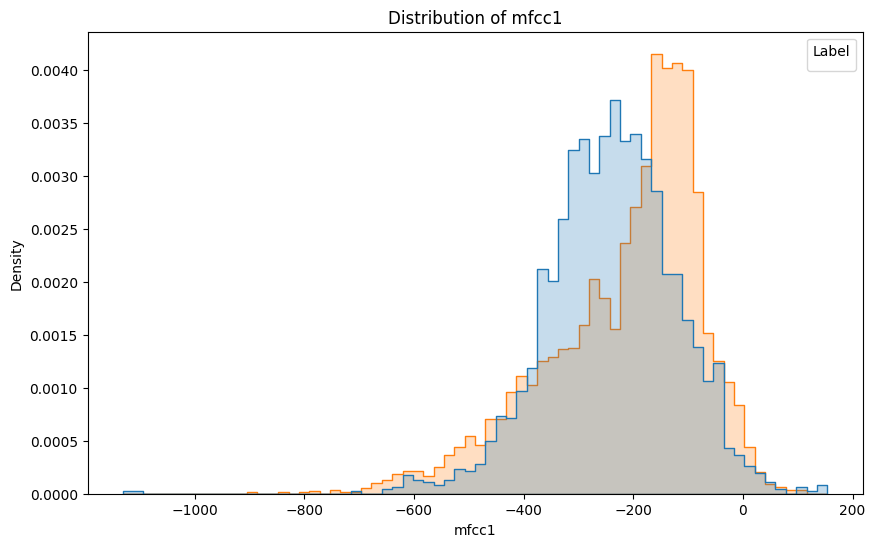

/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

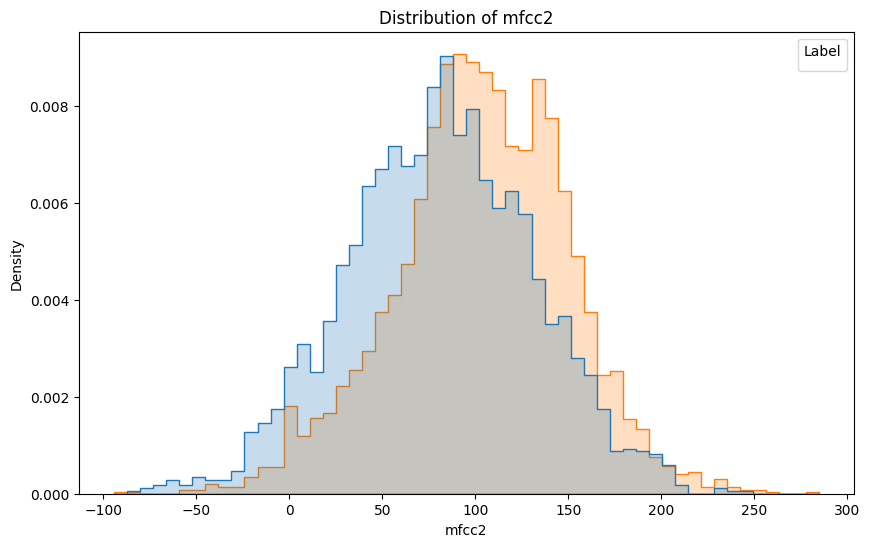

/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

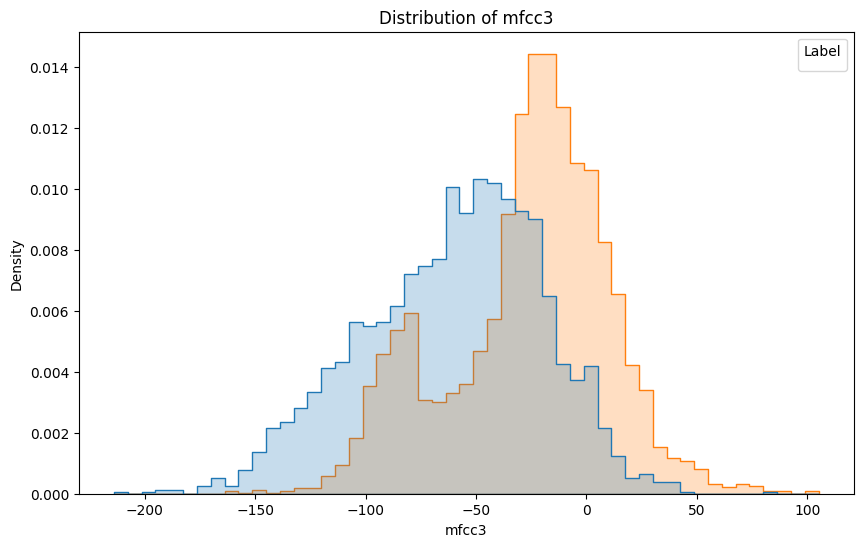

/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

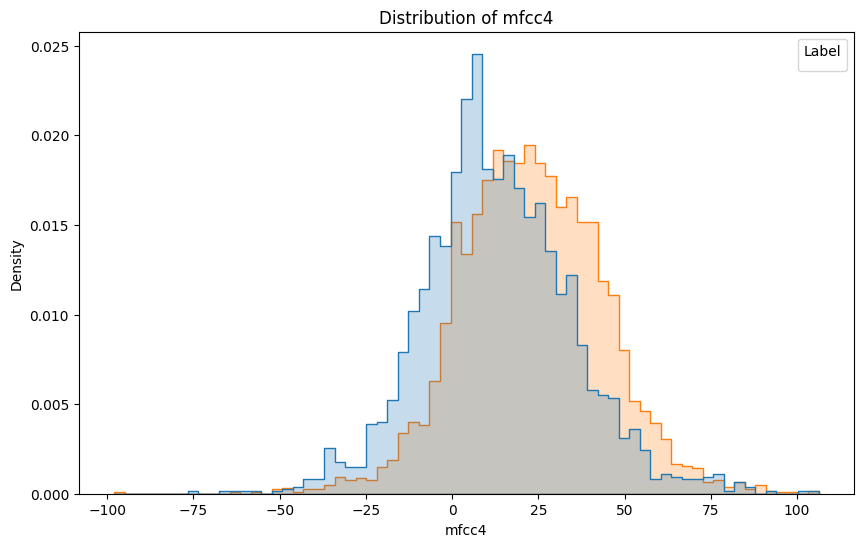

/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

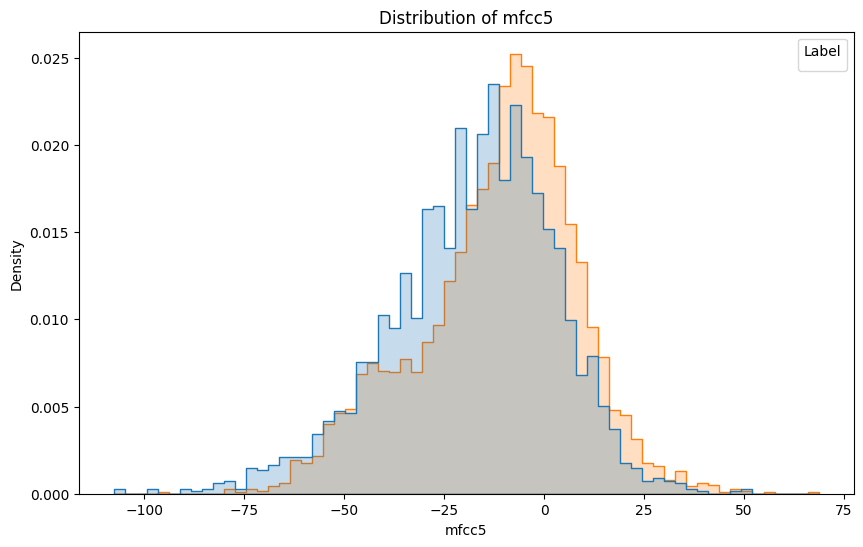

/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

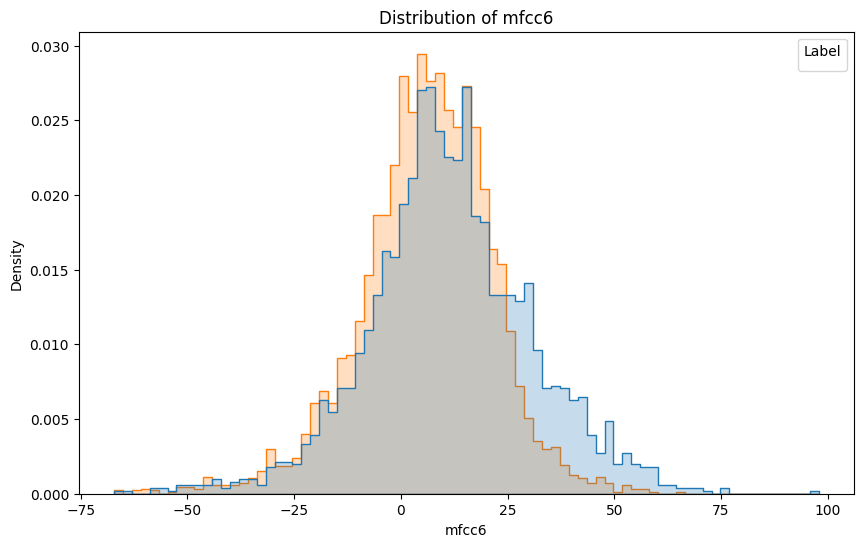

/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

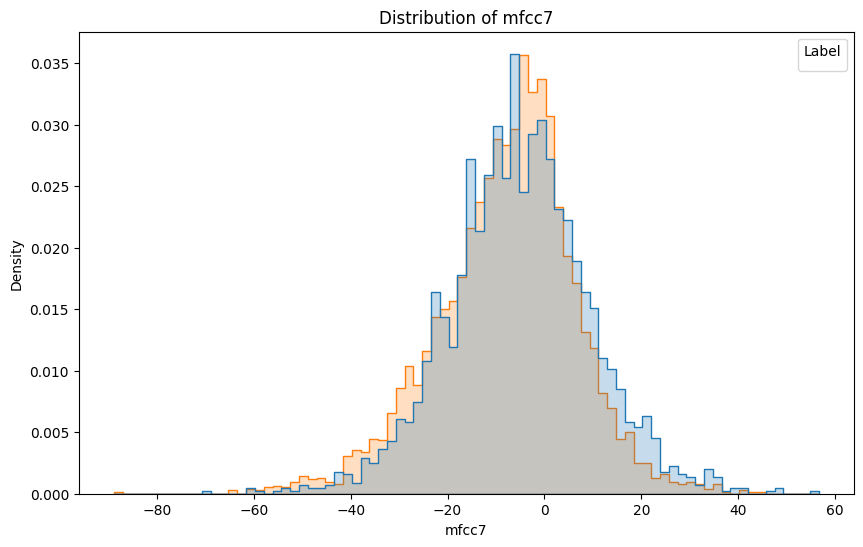

/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

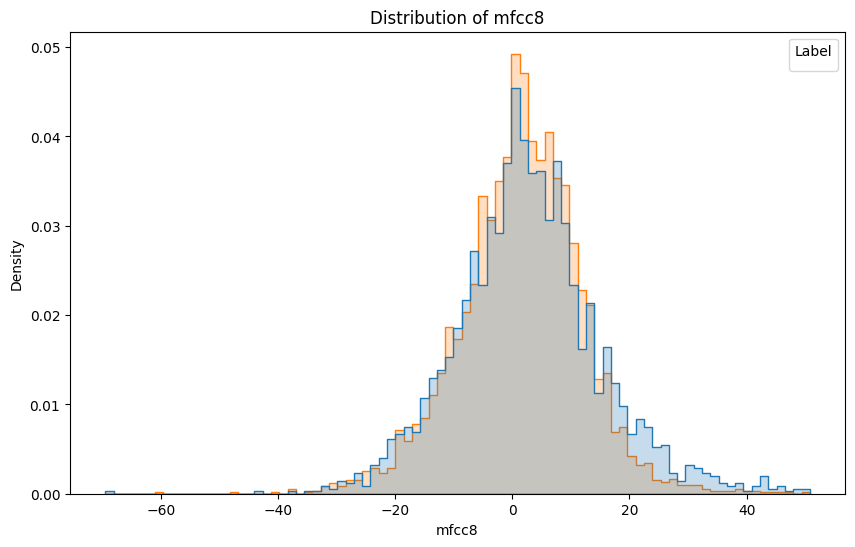

/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

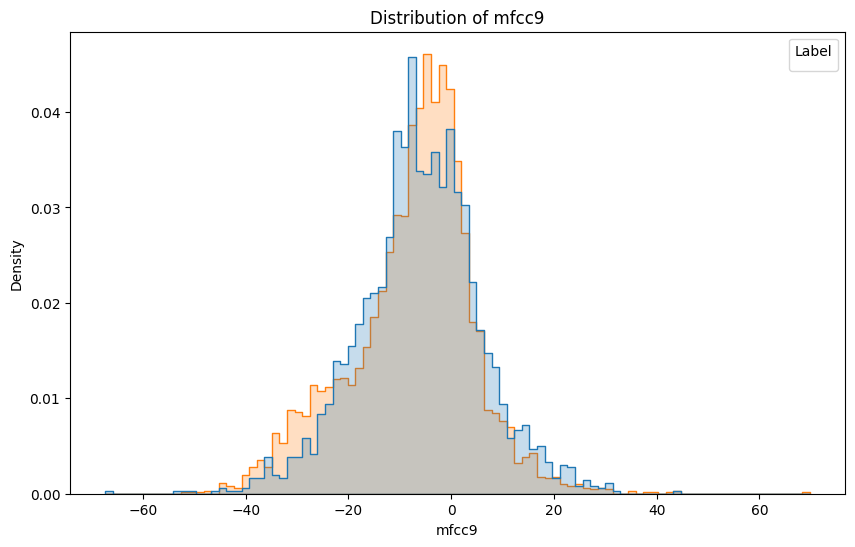

/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

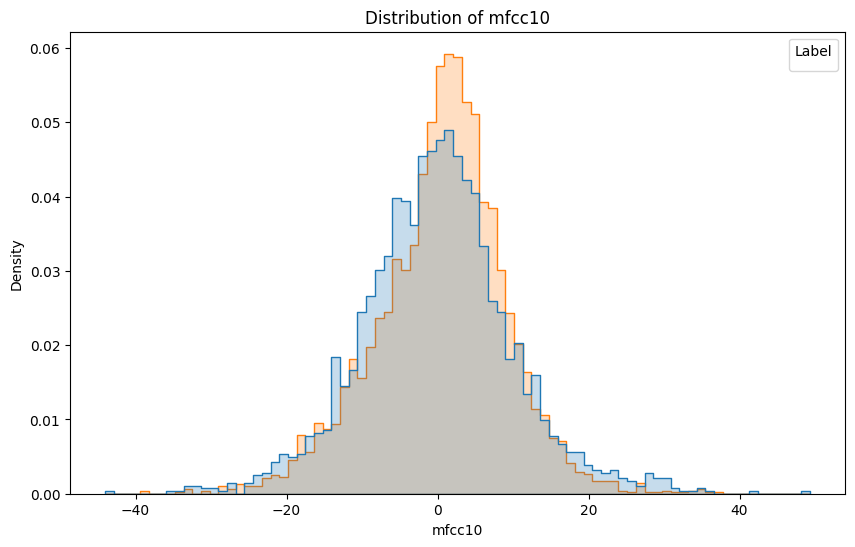

/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

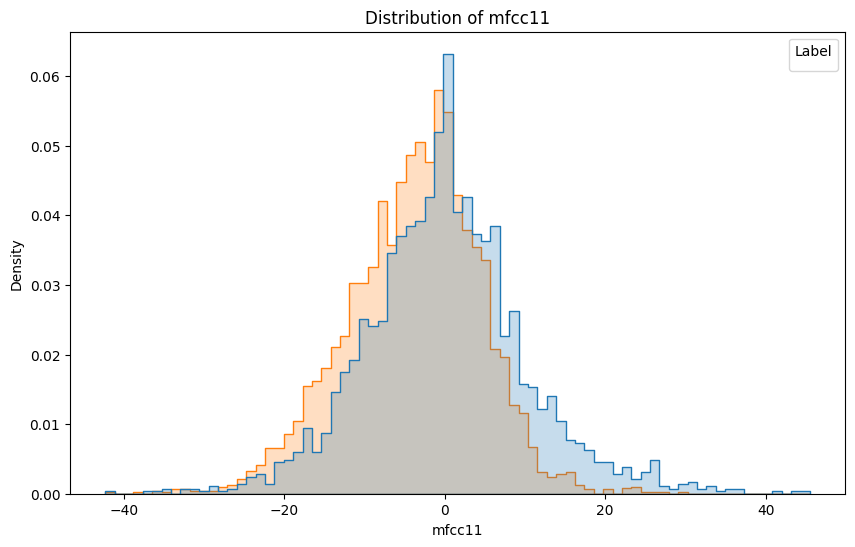

/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

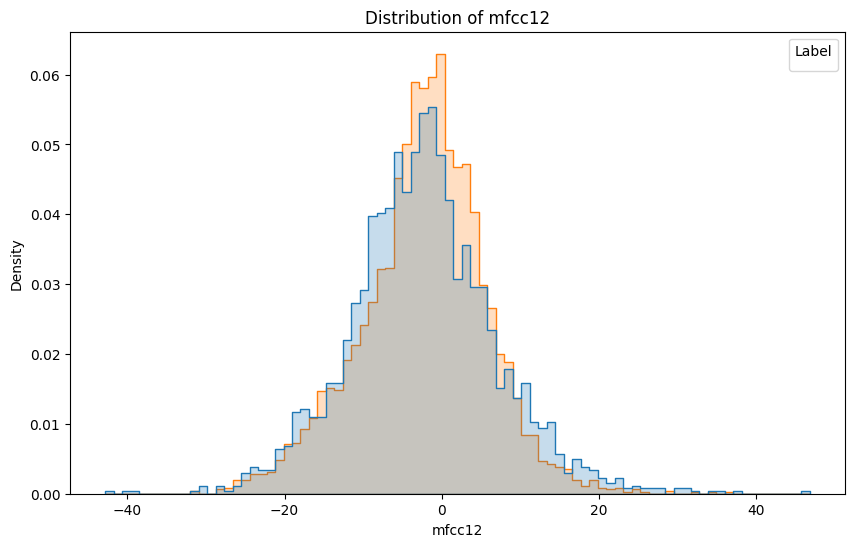

/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

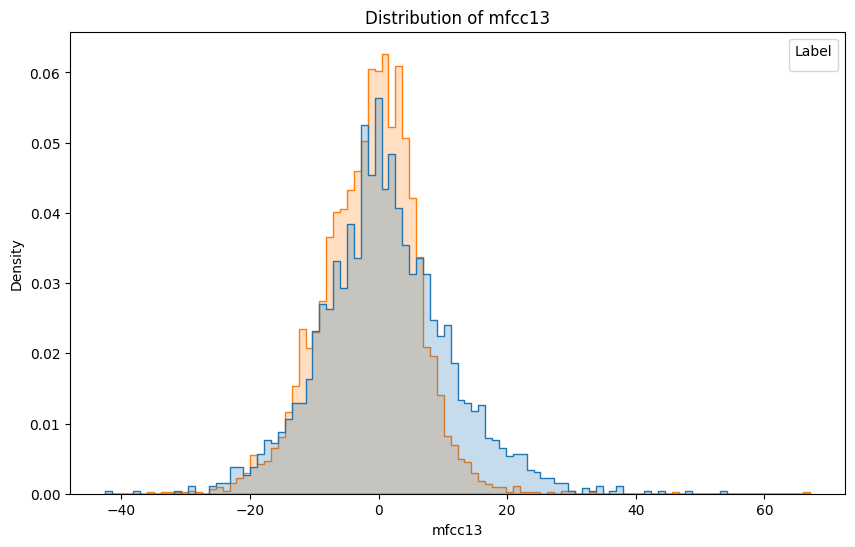

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

def plot_feature_distribution(X_screams, X_non_screams):
    # Check the shape of the input data
    print(f"Shape of X_screams: {X_screams.shape}")  # Should be (2445, 13, 100)
    print(f"Shape of X_non_screams: {X_non_screams.shape}")  # Should be (2445, 13, 100)

    # Generate feature names for MFCCs
    num_features = X_screams.shape[1]  # Should be 13
    feature_names = [f'mfcc{i+1}' for i in range(num_features)]

    # Average across the last dimension (time frames)
    X_screams_mean = np.mean(X_screams, axis=2)  # Shape: (2445, 13)
    X_non_screams_mean = np.mean(X_non_screams, axis=2)  # Shape: (2445, 13)

    # Convert to DataFrame for easier plotting
    df_screams = pd.DataFrame(X_screams_mean, columns=feature_names)
    df_screams['Label'] = 'Scream'

    df_non_screams = pd.DataFrame(X_non_screams_mean, columns=feature_names)
    df_non_screams['Label'] = 'Non-Scream'

    # Concatenate both DataFrames
    df = pd.concat([df_screams, df_non_screams], axis=0)

    # Plot histograms for each feature
    for feature in feature_names:
        plt.figure(figsize=(10, 6))
        sns.histplot(df, x=feature, hue='Label', element='step', stat='density', common_norm=False)
        plt.title(f'Distribution of {feature}')
        plt.xlabel(feature)
        plt.ylabel('Density')
        plt.legend(title='Label')
        plt.savefig(f'distribution_{feature}.png')  # Save the plot as a .png file
        plt.show()

# Call the function with your scream and non-scream data
plot_feature_distribution(X_screams, X_non_screams)


**Convert features to arrays and combine**

In [11]:
 
X = np.vstack([X_screams, X_non_screams])
y_screams = np.ones(len(X_screams))
y_non_screams = np.zeros(len(X_non_screams))
y = np.hstack([y_screams, y_non_screams])


In [12]:
print(X.shape)
print(y.shape)

(6621, 13, 100)
(6621,)


**Combine scream and non-scream features**

In [13]:


import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

 #Assuming X_screams and X_non_screams are already defined
#Example shapes: X_screams: (2445, 13, 100), X_non_screams: (2445, 13, 100)

# Combine the scream and non-scream features
X = np.vstack([X_screams, X_non_screams])

# Create labels for the data
y_screams = np.ones(len(X_screams))
y_non_screams = np.zeros(len(X_non_screams))
y = np.hstack([y_screams, y_non_screams])

# Reshape X to 2D for scaling (samples, features)
X_reshaped = X.reshape(X.shape[0], -1)  # Shape becomes (4880, 1300)

# Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_reshaped)

# If needed, reshape back to original 3D shape after scaling
# X_scaled_reshaped = X_scaled.reshape(X.shape[0], X.shape[1], -1)  # Uncomment if needed

# Handle class imbalance
sm = SMOTE(random_state=42)
X_res, y_res = sm.fit_resample(X_scaled, y)

# Check class distribution after SMOTE
unique, counts = np.unique(y_res, return_counts=True)
print("Class distribution after SMOTE:", dict(zip(unique, counts)))

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_res, y_res, test_size=0.2, random_state=42)

# Print shapes for verification
print("Training data shape:", X_train.shape)
print("Test data shape:", X_test.shape)
print("Training labels shape:", y_train.shape)
print("Test labels shape:", y_test.shape)


Class distribution after SMOTE: {0.0: 4176, 1.0: 4176}
Training data shape: (6681, 1300)
Test data shape: (1671, 1300)
Training labels shape: (6681,)
Test labels shape: (1671,)


In [14]:
X_train = X_train.reshape(X_train.shape[0], -1)  # Flatten to 2D
X_test = X_test.reshape(X_test.shape[0], -1)     # Flatten test data similarly



K-Fold Cross-Validation Results for SVM (k=5):
Average Accuracy: 0.8013768648193516
Average Sensitivity (Recall): 0.8012309978748927
Average Precision: 0.8017313529504729
Average F1 Score: 0.8012215728286669


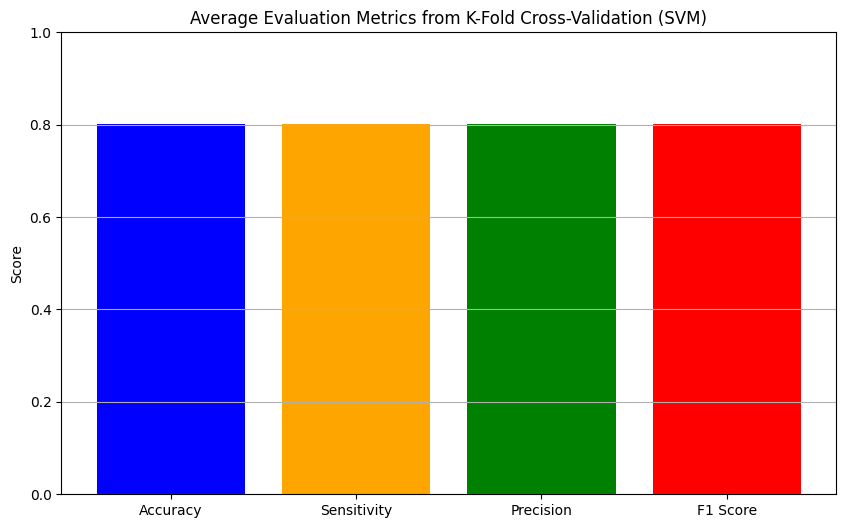

In [15]:
from sklearn.model_selection import KFold
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

# Initialize the SVM model with modified parameters
model_svm = SVC(
    kernel='linear',         # Changed to linear kernel
    C=0.1,                   # Reduced regularization parameter
    random_state=42          # Random state for reproducibility
)

# Define the number of folds
k = 5
kf = KFold(n_splits=k, shuffle=True, random_state=42)

# Lists to hold the metrics for each fold
accuracy_list = []
sensitivity_list = []
precision_list = []
f1_score_list = []

# Perform k-fold cross-validation
for train_index, test_index in kf.split(X_train):
    X_train_fold, X_test_fold = X_train[train_index], X_train[test_index]
    y_train_fold, y_test_fold = y_train[train_index], y_train[test_index]
    
    # Fit the model on the training fold
    model_svm.fit(X_train_fold, y_train_fold)
    
    # Predict on the test fold
    y_pred_fold = model_svm.predict(X_test_fold)
    
    # Calculate metrics for the fold
    accuracy_fold = accuracy_score(y_test_fold, y_pred_fold)
    sensitivity_fold = recall_score(y_test_fold, y_pred_fold, average='macro')
    precision_fold = precision_score(y_test_fold, y_pred_fold, average='macro')
    f1_fold = f1_score(y_test_fold, y_pred_fold, average='macro')
    
    # Append metrics to lists
    accuracy_list.append(accuracy_fold)
    sensitivity_list.append(sensitivity_fold)
    precision_list.append(precision_fold)
    f1_score_list.append(f1_fold)

# Calculate average metrics across all folds
avg_accuracy = np.mean(accuracy_list)
avg_sensitivity = np.mean(sensitivity_list)
avg_precision = np.mean(precision_list)
avg_f1_score = np.mean(f1_score_list)

# Print the average results
print(f"\nK-Fold Cross-Validation Results for SVM (k={k}):")
print(f"Average Accuracy: {avg_accuracy}")
print(f"Average Sensitivity (Recall): {avg_sensitivity}")
print(f"Average Precision: {avg_precision}")
print(f"Average F1 Score: {avg_f1_score}")

# Plot the metrics
metrics = ['Accuracy', 'Sensitivity', 'Precision', 'F1 Score']
avg_metrics = [avg_accuracy, avg_sensitivity, avg_precision, avg_f1_score]
plt.figure(figsize=(10, 6))
plt.bar(metrics, avg_metrics, color=['blue', 'orange', 'green', 'red'])
plt.ylim(0, 1)
plt.title('Average Evaluation Metrics from K-Fold Cross-Validation (SVM)')
plt.ylabel('Score')
plt.grid(axis='y')
plt.show()


Confusion Matrix for Fold 1:


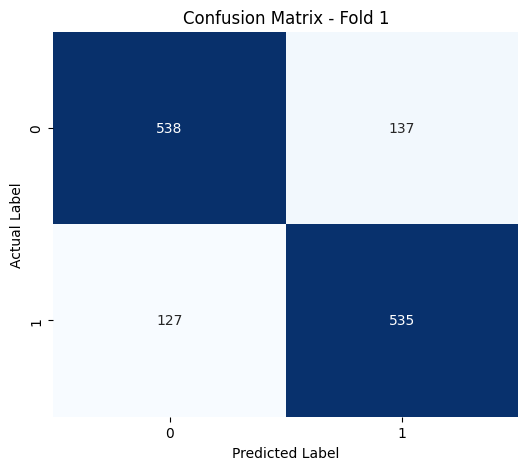


Confusion Matrix for Fold 2:


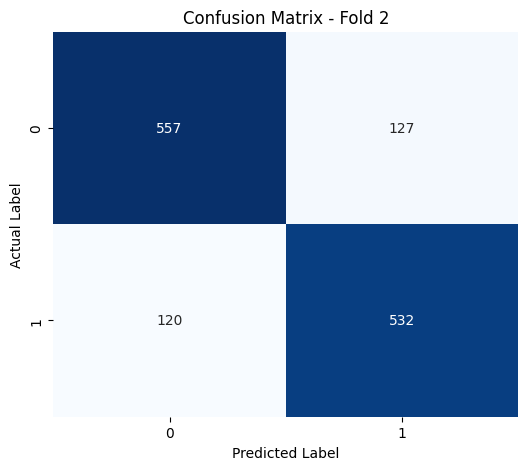


Confusion Matrix for Fold 3:


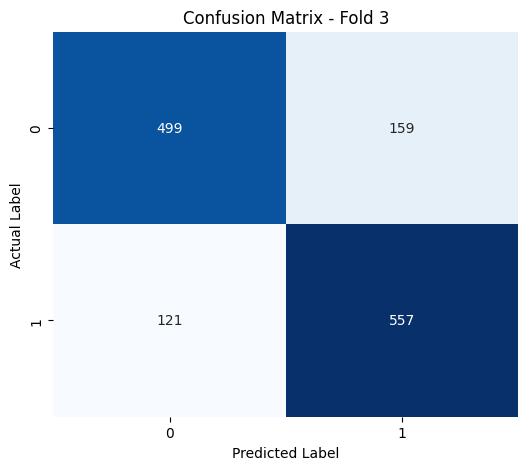


Confusion Matrix for Fold 4:


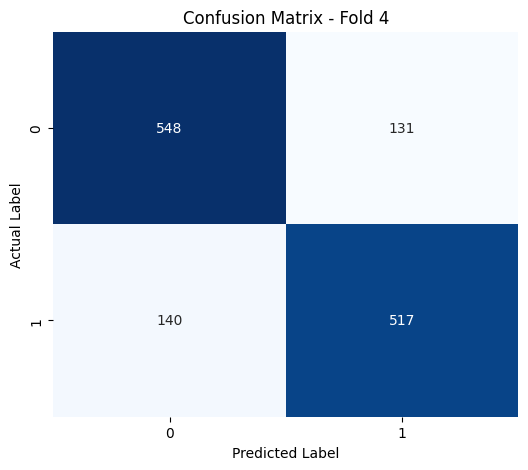


Confusion Matrix for Fold 5:


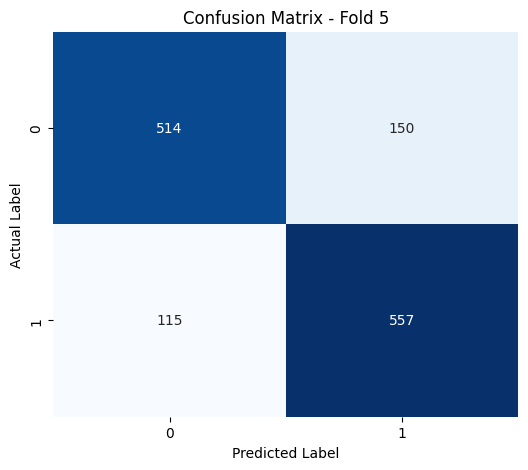

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Function to plot confusion matrix
def plot_confusion_matrix(cm, title='Confusion Matrix', cmap=plt.cm.Blues):
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, cbar=False)
    plt.title(title)
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')
    plt.show()

# Perform k-fold cross-validation
for fold, (train_index, test_index) in enumerate(kf.split(X_train), 1):
    X_train_fold, X_test_fold = X_train[train_index], X_train[test_index]
    y_train_fold, y_test_fold = y_train[train_index], y_train[test_index]
    
    # Fit the SVM model on the training fold
    model_svm.fit(X_train_fold, y_train_fold)
    
    # Predict on the test fold
    y_pred_fold_svm = model_svm.predict(X_test_fold)
    
    # Generate the confusion matrix
    cm_fold_svm = confusion_matrix(y_test_fold, y_pred_fold_svm)
    
    # Plot the confusion matrix for each fold
    print(f"\nConfusion Matrix for Fold {fold}:")
    plot_confusion_matrix(cm_fold_svm, title=f"Confusion Matrix - Fold {fold}")
    
    # Calculate and display the metrics (already calculated in previous steps)
    accuracy_fold_svm = accuracy_score(y_test_fold, y_pred_fold_svm)
    sensitivity_fold_svm = recall_score(y_test_fold, y_pred_fold_svm, average='macro')
    specificity_fold_svm = cm_fold_svm[0, 0] / (cm_fold_svm[0, 0] + cm_fold_svm[0, 1]) if (cm_fold_svm[0, 0] + cm_fold_svm[0, 1]) != 0 else 0
    



In [17]:
X_train = X_train.reshape(X_train.shape[0], -1)  # Flatten to 2D
X_test = X_test.reshape(X_test.shape[0], -1)     # Flatten test data similarly


K-Fold Cross-Validation Results for Random Forest (k=5):
Average Accuracy (RF): 0.8085622696267898
Average Sensitivity (RF): 0.8082331788530043
Average Precision (RF): 0.8112210618898619
Average F1 Score (RF): 0.8080068839192152


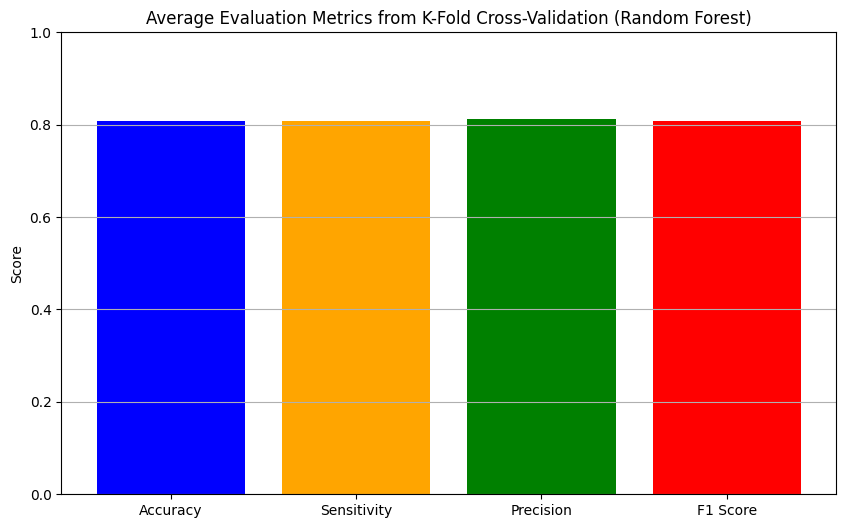

In [18]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix
from sklearn.model_selection import KFold
import numpy as np
import matplotlib.pyplot as plt

# Initialize the Random Forest model with modified parameters
model_rf = RandomForestClassifier(
    n_estimators=50,        # Reduced number of trees
    criterion='gini',    # Changed to entropy criterion
    max_depth=5,            # Limited max depth
    min_samples_split=5,    # Increased min samples to split
    random_state=42,
    n_jobs=-1
)

# Define the number of folds
k = 5
kf = KFold(n_splits=k, shuffle=True, random_state=42)

# Lists to hold the metrics for each fold
accuracy_list_rf = []
sensitivity_list_rf = []
precision_list_rf = []
f1_score_list_rf = []

# Perform k-fold cross-validation
for train_index, test_index in kf.split(X_train):
    X_train_fold, X_test_fold = X_train[train_index], X_train[test_index]
    y_train_fold, y_test_fold = y_train[train_index], y_train[test_index]
    
    # Fit the Random Forest model on the training fold
    model_rf.fit(X_train_fold, y_train_fold)
    
    # Predict on the test fold
    y_pred_fold_rf = model_rf.predict(X_test_fold)
    
    # Calculate metrics for the fold
    accuracy_fold_rf = accuracy_score(y_test_fold, y_pred_fold_rf)
    sensitivity_fold_rf = recall_score(y_test_fold, y_pred_fold_rf, average='macro')
    precision_fold_rf = precision_score(y_test_fold, y_pred_fold_rf, average='macro')
    f1_fold_rf = f1_score(y_test_fold, y_pred_fold_rf, average='macro')
    
    # Append metrics to lists
    accuracy_list_rf.append(accuracy_fold_rf)
    sensitivity_list_rf.append(sensitivity_fold_rf)
    precision_list_rf.append(precision_fold_rf)
    f1_score_list_rf.append(f1_fold_rf)

# Calculate average metrics across all folds for Random Forest
avg_accuracy_rf = np.mean(accuracy_list_rf)
avg_sensitivity_rf = np.mean(sensitivity_list_rf)
avg_precision_rf = np.mean(precision_list_rf)
avg_f1_score_rf = np.mean(f1_score_list_rf)

# Print the average results for Random Forest
print(f"\nK-Fold Cross-Validation Results for Random Forest (k={k}):")
print(f"Average Accuracy (RF): {avg_accuracy_rf}")
print(f"Average Sensitivity (RF): {avg_sensitivity_rf}")
print(f"Average Precision (RF): {avg_precision_rf}")
print(f"Average F1 Score (RF): {avg_f1_score_rf}")

# Plot the metrics
metrics_rf = ['Accuracy', 'Sensitivity', 'Precision', 'F1 Score']
avg_metrics_rf = [avg_accuracy_rf, avg_sensitivity_rf, avg_precision_rf, avg_f1_score_rf]
plt.figure(figsize=(10, 6))
plt.bar(metrics_rf, avg_metrics_rf, color=['blue', 'orange', 'green', 'red'])
plt.ylim(0, 1)
plt.title('Average Evaluation Metrics from K-Fold Cross-Validation (Random Forest)')
plt.ylabel('Score')
plt.grid(axis='y')
plt.show()

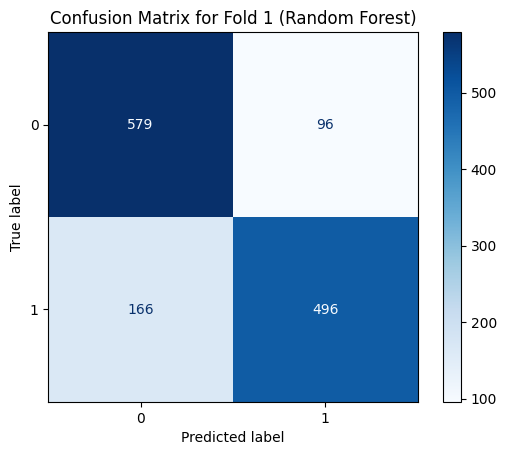

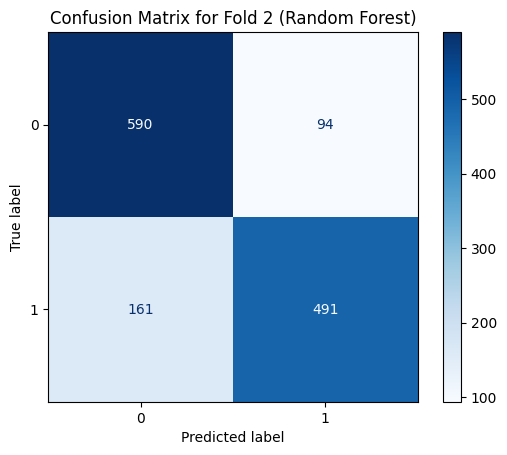

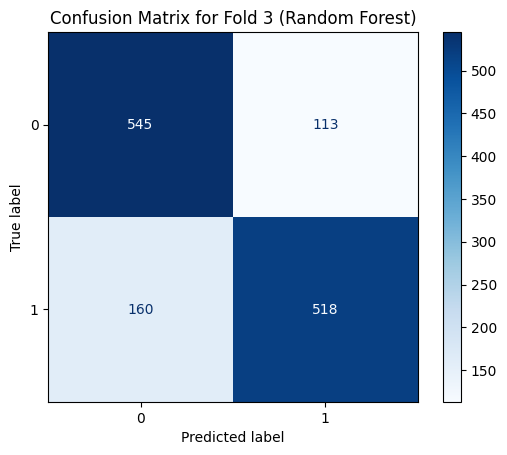

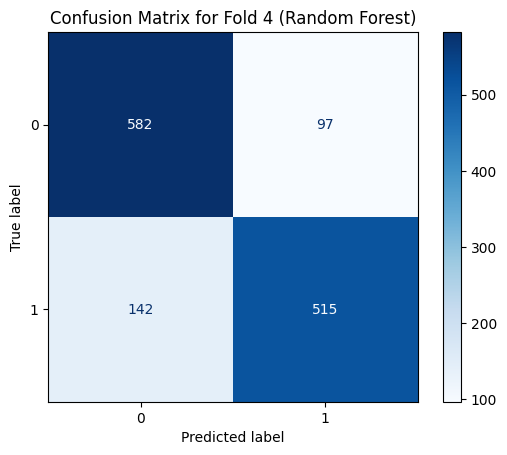

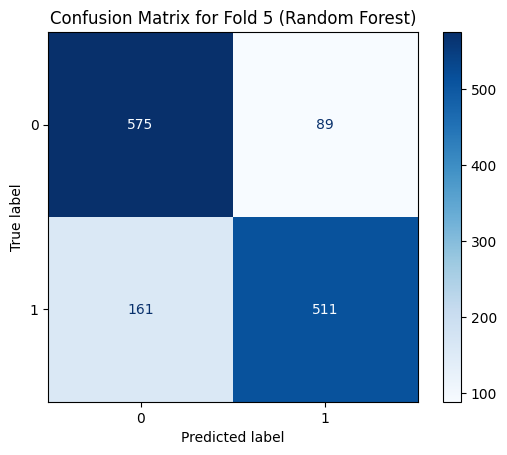

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay

# Perform k-fold cross-validation with confusion matrix plotting
for fold, (train_index, test_index) in enumerate(kf.split(X_train), 1):
    X_train_fold, X_test_fold = X_train[train_index], X_train[test_index]
    y_train_fold, y_test_fold = y_train[train_index], y_train[test_index]
    
    # Fit the Random Forest model on the training fold
    model_rf.fit(X_train_fold, y_train_fold)
    
    # Predict on the test fold
    y_pred_fold_rf = model_rf.predict(X_test_fold)
    
    # Calculate and print the confusion matrix for the fold
    cm = confusion_matrix(y_test_fold, y_pred_fold_rf)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    
    # Plot confusion matrix
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f"Confusion Matrix for Fold {fold} (Random Forest)")
    plt.show()


**NOW LETS DO WITH THE DEEP LEARNING MODEL CNN**

2024-10-17 15:33:53.926085: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-10-17 15:33:53.926268: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-10-17 15:33:54.027452: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Epoch 1/50
83/83 [==============================] - 44s 504ms/step - loss: 0.6082 - accuracy: 0.7553 - val_loss: 1.4441 - val_accuracy: 0.7517 - lr: 0.0010
Epoch 2/50
83/83 [==============================] - 42s 511ms/step - loss: 0.4438 - accuracy: 0.8170 - val_loss: 0.4593 - val_accuracy: 0.8309 - lr: 0.0010
Epoch 3/50
83/83 [==============================] - 41s 498ms/step - loss: 0.4011 - accuracy: 0.8304 - val_loss: 0.3478 - val_accuracy: 0.8558 - lr: 0.0010
Epoch 4/50
83/83 [==============================] - 43s 519ms/step - loss: 0.3697 - accuracy: 0.8448 - val_loss: 0.3873 - val_accuracy: 0.8377 - lr: 0.0010
Epoch 5/50
83/83 [==============================] - 43s 524ms/step - loss: 0.3264 - accuracy: 0.8597 - val_loss: 0.3075 - val_accuracy: 0.8755 - lr: 0.0010
Epoch 6/50
83/83 [==============================] - 42s 512ms/step - loss: 0.3234 - accuracy: 0.8656 - val_loss: 0.3292 - val_accuracy: 0.8642 - lr: 0.0010
Epoch 7/50
83/83 [==============================] - 43s 523ms/st

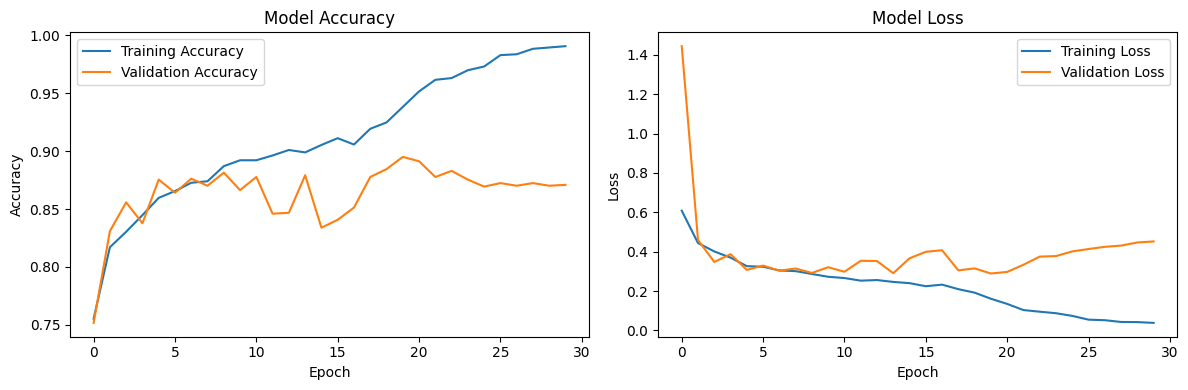

In [20]:

import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from sklearn.model_selection import train_test_split
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Constants
NUM_CLASSES = 2
TARGET_LENGTH = 100

# Prepare the data for training
X = np.concatenate((X_screams, X_non_screams), axis=0)
y = np.array([1] * X_screams.shape[0] + [0] * X_non_screams.shape[0])

# Reshape the input data for CNN: (num_samples, height, width, channels)
X = X.reshape(X.shape[0], X.shape[1], X.shape[2], 1)

# Split the data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# Build the CNN Model
model = Sequential([
    Conv2D(64, (3, 3), activation='relu', input_shape=(X.shape[1], X.shape[2], 1), padding='same'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    
    Conv2D(256, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    
    Flatten(),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(NUM_CLASSES, activation='softmax')
])

# Compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Define callbacks
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=1e-6)

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,  # Increased number of epochs
    batch_size=64,  # Adjusted batch size
    callbacks=[early_stopping, reduce_lr]
)

# Evaluate the model
loss, accuracy = model.evaluate(X_val, y_val)
print(f'Validation Loss: {loss}')
print(f'Validation Accuracy: {accuracy}')

# Plot training history
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [21]:
print(f'Model Accuracy: {accuracy}')

Model Accuracy: 0.8950943350791931


42/42 [==============================] - 3s 56ms/step
Precision: 0.9162790697674419
Recall: 0.7927565392354124
F1 Score: 0.8500539374325782


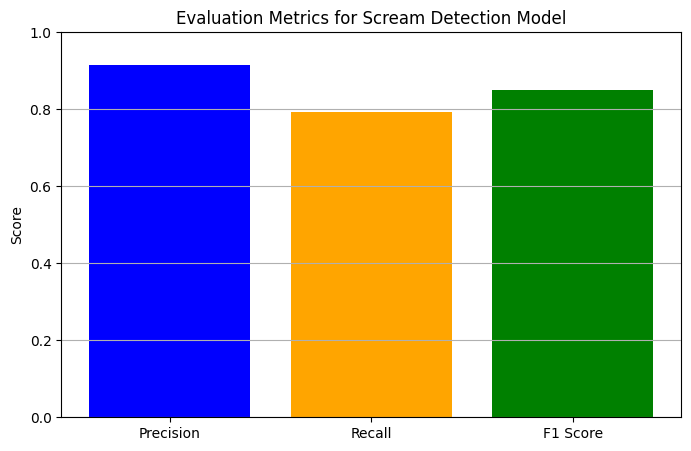

In [22]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt

# Generate predictions on the validation set
y_pred_prob = model.predict(X_val)
y_pred = np.argmax(y_pred_prob, axis=1)  # Get class labels from probabilities

# Calculate evaluation metrics
precision = precision_score(y_val, y_pred)
recall = recall_score(y_val, y_pred)
f1 = f1_score(y_val, y_pred)
cm = confusion_matrix(y_val, y_pred)

# Print evaluation metrics
print(f'Precision: {precision}')
print(f'Recall: {recall}')
print(f'F1 Score: {f1}')
# Optionally, you can also plot precision, recall, and F1 score
metrics = ['Precision', 'Recall', 'F1 Score']
values = [precision, recall, f1]

plt.figure(figsize=(8, 5))
plt.bar(metrics, values, color=['blue', 'orange', 'green'])
plt.ylim(0, 1)
plt.title('Evaluation Metrics for Scream Detection Model')
plt.ylabel('Score')
plt.grid(axis='y')
plt.show()

42/42 [==============================] - 2s 57ms/step


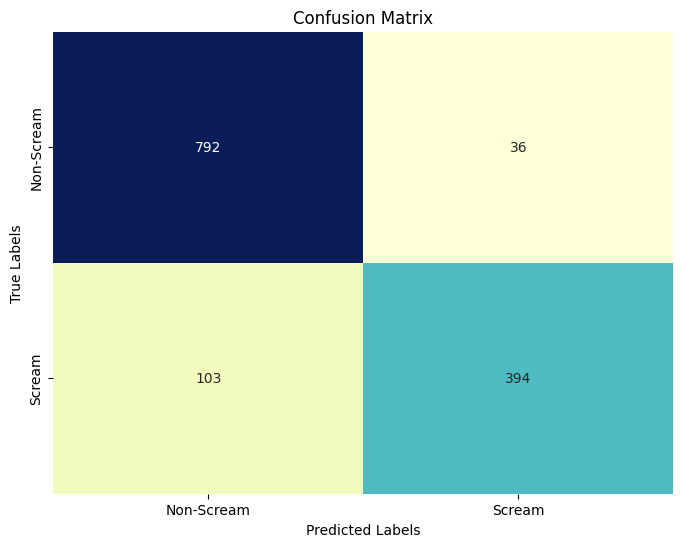

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Make predictions on the validation set
y_pred = model.predict(X_val)
y_pred_classes = np.argmax(y_pred, axis=1)  # Get class labels from predictions

# Calculate the confusion matrix
cm = confusion_matrix(y_val, y_pred_classes)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu', cbar=False,
            xticklabels=['Non-Scream', 'Scream'], 
            yticklabels=['Non-Scream', 'Scream'])
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()


In [24]:
model.save('/kaggle/working/scream_detector_model.h5')  # Save as HDF5 file

# Save the scaler
joblib.dump(scaler, '/kaggle/working/scaler.pkl')

/opt/conda/lib/python3.10/site-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


['/kaggle/working/scaler.pkl']

**Predicting the Human Scream based on the Audio**

In [25]:
X_train = X_train.reshape(X_train.shape[0], -1)  # Flatten to 2D
X_test = X_test.reshape(X_test.shape[0], -1)     # Flatten test data similarly

In [26]:
import numpy as np
import librosa

RATE = 44100  # Set your sample rate, e.g., 44100 Hz
DURATION = 3  # Set the duration for audio clips in seconds

def preprocess_audio(file_path):
    # Load the audio file
    y, sr = librosa.load(file_path, sr=RATE, duration=DURATION)
    
    # Pad or truncate the audio to the desired length
    if len(y) > RATE * DURATION:
        y = y[:RATE * DURATION]
    else:
        y = np.pad(y, (0, max(0, RATE * DURATION - len(y))))
    
    # Generate Mel spectrogram with 13 Mel bands to match the model's expected input
    mel_spectrogram = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=13)
    
    # Convert to decibels
    mel_spectrogram = librosa.power_to_db(mel_spectrogram, ref=np.max)
    
    # Normalize
    mel_spectrogram = (mel_spectrogram - mel_spectrogram.min()) / (mel_spectrogram.max() - mel_spectrogram.min())
    
    # Truncate or pad the time dimension to 100 steps
    if mel_spectrogram.shape[1] > 100:
        mel_spectrogram = mel_spectrogram[:, :100]
    else:
        mel_spectrogram = np.pad(mel_spectrogram, ((0, 0), (0, 100 - mel_spectrogram.shape[1])), mode='constant')
    
    # Reshape for model input (assuming the model expects a 4D input: batch_size, n_mels, time_steps, channels)
    mel_spectrogram = mel_spectrogram.reshape(1, 13, 100, 1)
    
    return mel_spectrogram


In [27]:
def predict_audio(file_path):
    # Preprocess the audio
    preprocessed_audio = preprocess_audio(file_path)
    
    # Make a prediction
    prediction = model.predict(preprocessed_audio)
    predicted_class = 1 if prediction[0][0] > 0.5 else 0  # Threshold for binary classification
    
    return 'Scream' if predicted_class == 1 else 'Not Scream'

# Example usage
import os

audio_folder = '/kaggle/input/prediction/'  # Replace with your folder path

# Iterate over all audio files in the folder
for file_name in os.listdir(audio_folder):
    if file_name.endswith('.wav'):  # Check for .wav files
        audio_file_path = os.path.join(audio_folder, file_name)
        try:
            result = predict_audio(audio_file_path)
            print(f'The audio file "{file_name}" is classified as: {result}')
        except Exception as e:
            print(f'Error processing "{file_name}": {str(e)}')

1/1 [==============================] - 0s 33ms/step
The audio file "-ECK_BisOLM_out.wav" is classified as: Scream
1/1 [==============================] - 0s 33ms/step
The audio file "-Wu-WkTumEM_out.wav" is classified as: Scream
1/1 [==============================] - 0s 34ms/step
The audio file "-Dj2PfPmynQ_out.wav" is classified as: Scream
1/1 [==============================] - 0s 36ms/step
The audio file "-HN5kqCKpEA_out.wav" is classified as: Scream
1/1 [==============================] - 0s 34ms/step
The audio file "-5Jlimvsuwo_out.wav" is classified as: Scream
1/1 [==============================] - 0s 33ms/step
The audio file "-KiAK66YwW8_out.wav" is classified as: Scream
1/1 [==============================] - 0s 33ms/step
The audio file "-CgdUiJaNdU_out.wav" is classified as: Scream
